In [ ]:
# ==============================================================================
# Purpose:
#   Plot spectrum-flow MFI differences (NHB vs NHW) for selected markers across
#   specific immune cell subsets, with per-panel Mann–Whitney p-value (star)
#   annotations, arranged as a single multi-panel grid (rows=cell types,
#   cols=markers) for compact, publication-ready figures.
#
# Steps:
#   1) Load clinical metadata and flow MFI table; harmonize Patient ID formats.
#   2) Merge metadata with MFI features; subset to HR+/HER2- patients.
#   3) Define (celltype × marker) targets and extract matching feature columns.
#   4) Convert wide MFI table to long format; parse feature strings into:
#        - celltype_raw (as encoded in column name)
#        - protein (marker), then rename to biological names (e.g., CD279→PD-1).
#   5) For each (celltype_raw × protein), draw:
#        - boxplot + stripplot by Race & Ethnicity (NHW vs NHB)
#        - Mann–Whitney annotation (stars) with small font in-panel.
#   6) Arrange panels into a single grid (rows=cell types; cols=markers),
#      label y-axis as "MFI" on the first column only, and save to PDF.
#   7) Repeat the same workflow for B-cell homing/activation markers (HLA-DR,
#      CCR7, CXCR5) and save a second figure.
# ==============================================================================

# Header

In [1]:
import pandas as pd
from pandas.api.types import CategoricalDtype
import numpy as np
from math import *
from collections import Counter
import pickle as pkl
import argparse

# import scanpy as sc
# import scvelo as scv

import os
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# import scrublet as scr
import scipy.io
import matplotlib.pyplot as plt

In [2]:
os.chdir('../')

# Load data

In [3]:
import re


def normalize_patient_id(x):
    s = str(x).strip()

    # "31 (M)" → "31-M"
    s = re.sub(r'(\d+)\s*\(([^)]+)\)', r'\1-\2', s)

    # split number and optional suffix
    m = re.match(r'(\d+)(.*)', s)
    if not m:
        return s

    num, suffix = m.groups()
    return f"{int(num):02d}{suffix}"

meta = pd.read_excel(
    'data/12_flow_data_mfi/2025.2.25 IW Invasive clinical metadata.xlsx',
    sheet_name='flow'
)


meta['Patient ID'] = meta['Patient ID'].apply(normalize_patient_id)
meta['Race & Ethnicity'] = (
    meta['Race & Ethnicity']
      .astype(str)
      .str.strip()          # remove leading/trailing spaces and newlines
)

print(Counter(meta['Race & Ethnicity']))
meta

Counter({'NHB': 39, 'NHW': 38})


,Patient ID,Age,Race & Ethnicity,Subtype,Diabetes,Obesity
0,02,34,NHW,"HR+,HER2-",No,No
1,03,74,NHW,"HR+,HER2-",No,Yes
2,04,47,NHB,"HR+,HER2-",No,Yes
3,05,33,NHW,"HR+,HER2+",No,No
4,06,70,NHW,"HR+,HER2-",No,No
...,...,...,...,...,...,...
72,58-E,63,NHW,"HR+,HER2-",No,No
73,06-D,54,NHW,"HR+,HER2+",No,No
74,64-M,46,NHB,"HR+,HER2+",unknown,unknown
75,67-M,55,NHB,"HR+,HER2+",unknown,unknown


In [4]:
meta[meta['Subtype']=='HR+,HER2-']['Patient ID'].unique()

array(['02', '03', '04', '06', '10', '11', '19', '21', '22', '23', '25',
       '26', '27', '28', '29', '31', '36', '37', '38', '41', '44', '45',
       '50', '51', '55', '56', '57', '64', '66', '69', '70', '71', '73',
       '75', '76', '77', '81', '85', '90', '99', '100', '101', '106',
       '108', '58-E'], dtype=object)

In [5]:
df = pd.read_csv('data/12_flow_data_mfi/Ritah_FlowData_Cancer_MND-SCALED_MFI.csv', index_col=0)
df

,CD45+ Cells|SSC-H|mean,[Lymphocytes]|SSC-H|mean,[NKT] (CD3+ / CD56+)|SSC-H|mean,[NK cells]|SSC-H|mean,[Mature NK Cells]|SSC-H|mean,{CD94+ Mature NK}|SSC-H|mean,{CD158+ Mature NK}|SSC-H|mean,{CD159+ Mature NK}|SSC-H|mean,{CD314+ Mature NK}|SSC-H|mean,{CD335+ Mature NK}|SSC-H|mean,...,[Classical Monocytes - Normal]|flowcut-passed|mean,[Classical Monocytes - Immunodepressed]|flowcut-passed|mean,[Non-Classical Monocytes]|flowcut-passed|mean,[Non-classical Monocytes - Normal]|flowcut-passed|mean,[Non-classical Monocytes - Immunodepressed]|flowcut-passed|mean,[cDC3]|flowcut-passed|mean,[pDCs]|flowcut-passed|mean,[cDC2]|flowcut-passed|mean,[cDC1]|flowcut-passed|mean,[Basophils]|flowcut-passed|mean
file,,,,,,,,,,,,,,,,,,,,,
02.fcs,411464,328818,403363,396230,400452,401343,402222,412552.0,402470,407946,...,1,1.0,1,1,1,1,1,NaN,1,1.0
03.fcs,372048,325935,374606,409626,413357,414263,411713,423088.0,416213,417651,...,1,1.0,1,1,1,1,1,1.0,1,1.0
4.fcs,508009,362597,436605,450157,446363,446892,443015,446183.0,447445,454270,...,1,1.0,1,1,1,1,1,1.0,1,1.0
05.fcs,378629,345075,403399,429491,435510,435878,432263,444642.0,438020,438309,...,1,1.0,1,1,1,1,1,NaN,1,1.0
06-D.fcs,448120,375342,461851,432770,423151,422941,430753,415181.0,423637,423451,...,1,1.0,1,1,1,1,1,1.0,1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100.fcs,395074,349970,420696,415252,436835,437304,439937,446946.0,439225,458106,...,1,1.0,1,1,1,1,1,1.0,1,1.0
101.fcs,355230,326121,374073,392373,416354,416490,415480,420141.0,417131,431519,...,1,1.0,1,1,1,1,1,NaN,1,1.0
104.fcs,371694,340069,426854,429712,432243,432604,436227,437619.0,432496,439970,...,1,1.0,1,1,1,1,1,1.0,1,1.0


In [6]:
# df['Patient ID'] = (
#     df.index.astype(str)
#     .str.extract(r'\]\s*([^\.\s]+)\.fcs', expand=False)
# )

df['Patient ID'] = (
    df.index.str.replace(r"\.fcs$", "", regex=True)
      .str.replace(r'^(\d)(\D|$)', r'0\1\2', regex=True)
).tolist()

df['Patient ID']

file
02.fcs        02
03.fcs        03
4.fcs         04
05.fcs        05
06-D.fcs    06-D
            ... 
100.fcs      100
101.fcs      101
104.fcs      104
106.fcs      106
108.fcs      108
Name: Patient ID, Length: 77, dtype: object

In [7]:
dfp = pd.merge(
    meta, df,
    on='Patient ID'
)

dfp

,Patient ID,Age,Race & Ethnicity,Subtype,Diabetes,Obesity,CD45+ Cells|SSC-H|mean,[Lymphocytes]|SSC-H|mean,[NKT] (CD3+ / CD56+)|SSC-H|mean,[NK cells]|SSC-H|mean,...,[Classical Monocytes - Normal]|flowcut-passed|mean,[Classical Monocytes - Immunodepressed]|flowcut-passed|mean,[Non-Classical Monocytes]|flowcut-passed|mean,[Non-classical Monocytes - Normal]|flowcut-passed|mean,[Non-classical Monocytes - Immunodepressed]|flowcut-passed|mean,[cDC3]|flowcut-passed|mean,[pDCs]|flowcut-passed|mean,[cDC2]|flowcut-passed|mean,[cDC1]|flowcut-passed|mean,[Basophils]|flowcut-passed|mean
0,02,34,NHW,"HR+,HER2-",No,No,411464,328818,403363,396230,...,1,1.0,1,1,1,1,1,NaN,1,1.0
1,03,74,NHW,"HR+,HER2-",No,Yes,372048,325935,374606,409626,...,1,1.0,1,1,1,1,1,1.0,1,1.0
2,04,47,NHB,"HR+,HER2-",No,Yes,508009,362597,436605,450157,...,1,1.0,1,1,1,1,1,1.0,1,1.0
3,05,33,NHW,"HR+,HER2+",No,No,378629,345075,403399,429491,...,1,1.0,1,1,1,1,1,NaN,1,1.0
4,06,70,NHW,"HR+,HER2-",No,No,478769,355077,423323,437615,...,1,1.0,1,1,1,1,1,NaN,1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,58-E,63,NHW,"HR+,HER2-",No,No,413542,338187,442362,429242,...,1,1.0,1,1,1,1,1,1.0,1,1.0
71,06-D,54,NHW,"HR+,HER2+",No,No,448120,375342,461851,432770,...,1,1.0,1,1,1,1,1,1.0,1,1.0
72,64-M,46,NHB,"HR+,HER2+",unknown,unknown,400111,344239,419916,437414,...,1,1.0,1,1,1,1,1,NaN,1,1.0
73,67-M,55,NHB,"HR+,HER2+",unknown,unknown,414536,346654,400491,409160,...,1,1.0,1,1,1,1,1,1.0,1,1.0


In [8]:
dfp = dfp[
    (dfp['Subtype']=='HR+,HER2-') &
    (dfp['Patient ID'] != '29') # outlier sample, 29-I / Pool137_32
]

In [9]:
Counter(dfp['Race & Ethnicity'])

Counter({'NHW': 26, 'NHB': 17})

In [10]:
dfp.to_csv('data/12_flow_data_mfi/zenodo_meta_mnd.csv')

## Find sample overlap

scRNA vs flow

In [10]:
df = pd.read_csv('data/12_flow_data_mfi/zenodo_meta_mnd.csv', index_col=0)
df

,Patient ID,Age,Race & Ethnicity,Subtype,Diabetes,Obesity,CD45+ Cells|SSC-H|mean,[Lymphocytes]|SSC-H|mean,[NKT] (CD3+ / CD56+)|SSC-H|mean,[NK cells]|SSC-H|mean,...,[Classical Monocytes - Normal]|flowcut-passed|mean,[Classical Monocytes - Immunodepressed]|flowcut-passed|mean,[Non-Classical Monocytes]|flowcut-passed|mean,[Non-classical Monocytes - Normal]|flowcut-passed|mean,[Non-classical Monocytes - Immunodepressed]|flowcut-passed|mean,[cDC3]|flowcut-passed|mean,[pDCs]|flowcut-passed|mean,[cDC2]|flowcut-passed|mean,[cDC1]|flowcut-passed|mean,[Basophils]|flowcut-passed|mean
0,02,34,NHW,"HR+,HER2-",No,No,411464,328818,403363,396230,...,1,1.0,1,1,1,1,1,NaN,1,1.0
1,03,74,NHW,"HR+,HER2-",No,Yes,372048,325935,374606,409626,...,1,1.0,1,1,1,1,1,1.0,1,1.0
2,04,47,NHB,"HR+,HER2-",No,Yes,508009,362597,436605,450157,...,1,1.0,1,1,1,1,1,1.0,1,1.0
4,06,70,NHW,"HR+,HER2-",No,No,478769,355077,423323,437615,...,1,1.0,1,1,1,1,1,NaN,1,1.0
5,10,79,NHW,"HR+,HER2-",No,No,443681,337451,358750,413235,...,1,1.0,1,1,1,1,1,NaN,1,1.0
6,11,45,NHB,"HR+,HER2-",No,Yes,420354,366311,428440,423344,...,1,1.0,1,1,1,1,1,1.0,1,1.0
9,19,48,NHW,"HR+,HER2-",No,No,361353,324332,401573,442597,...,1,1.0,1,1,1,1,1,1.0,1,1.0
10,21,72,NHW,"HR+,HER2-",No,No,451647,381397,434094,442491,...,1,1.0,1,1,1,1,1,NaN,1,1.0
11,22,41,NHW,"HR+,HER2-",No,No,438289,369352,415364,423188,...,1,1.0,1,1,1,1,1,NaN,1,1.0
12,23,46,NHW,"HR+,HER2-",No,Yes,400981,350264,440306,406984,...,1,1.0,1,1,1,1,1,1.0,1,1.0


In [11]:
# check cohort overlap (scRNA vs flow)

master = pd.read_csv(
    'data/12_flow_data_mfi/data_avail_invasivecancer.csv'
)

master

,Patient ID,Oncore ID,SMB#,Date of birth,Blood collection date,Age at blood collection,Race & Ethnicity,Combined hormone receptor subtype,Study,Weathering Flow,Weathering Olink,Weathering scRNAseq,Aging Flow,Aging Olink,Can b e used for Aging scRNAseq
0,1,297387,NaN,4/2/1990,8/12/2021,31,NHW,TNBC,93-085 IW,No,Yes,No,No,Yes,No
1,2,297662,NaN,2/12/1987,8/19/2021,34,NHW,"HR+,HER2-",93-085 IW,Yes,Yes,Yes,Yes,Yes,Yes
2,3,298289,NaN,8/30/1947,9/2/2021,74,NHW,"HR+,HER2-",93-085 IW,Yes,Yes,No,Yes,Yes,No
3,4,298387,NaN,8/14/1974,9/7/2021,47,NHB,"HR+,HER2-",93-085 IW,Yes,Yes,Yes,No,No,No
4,5,298417,NaN,10/18/1987,9/7/2021,33,NHW,"HR+,HER2+",93-085 IW,Yes,Yes,No,Yes,Yes,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,58 (E),310857,NaN,12/25/1958,5/19/2022,63,NHW,"HR+,HER2-",93-085 ER+ cohort,Yes,Yes,Yes,No,No,No
86,6 (D),302882,NaN,3/10/1967,12/8/2021,54,NHW,"HR+,HER2+",93-085 (former DCIS),Yes,Yes,No,No,No,No
87,64 (M),313744,NaN,7/23/1975,7/21/2022,46,NHB,"HR+,HER2+",MARGOT,Yes,Yes,No,No,No,No
88,67 (M),314545,NaN,1/7/1967,8/9/2022,55,NHB,"HR+,HER2+",MARGOT,Yes,Yes,No,No,No,No


In [12]:
master[
    (master['Combined hormone receptor subtype']=='HR+,HER2-') &
    (master['Weathering Flow'] == 'Yes')
    ]['Patient ID'].unique()

array(['2', '3', '4', '6', '10', '11', '19', '21', '22', '23', '25', '26',
       '27', '28', '29', '31', '35', '36', '37', '38', '41', '44', '45',
       '50', '51', '55', '56', '57', '64', '66', '69', '70', '71', '73',
       '75', '76', '77', '81', '85', '90', '99', '100', '101', '106',
       '108', '58 (E)'], dtype=object)

In [13]:
master[
    (master['Combined hormone receptor subtype']=='HR+,HER2-') &
    (master['Weathering Flow'] == 'Yes') &
    (master['Weathering scRNAseq'] == 'Yes') 
    ]['Patient ID'].unique()

array(['2', '4', '11', '19', '23', '26', '27', '28', '29', '31', '35',
       '36', '37', '38', '45', '50', '55', '56', '57', '64', '66', '71',
       '73', '76', '77', '99', '101', '58 (E)'], dtype=object)

In [14]:
df['Patient ID'].unique()

array(['02', '03', '04', '06', '10', '11', '19', '21', '22', '23', '25',
       '26', '27', '28', '31', '36', '37', '38', '41', '44', '45', '50',
       '51', '55', '56', '57', '64', '66', '69', '70', '71', '73', '75',
       '76', '77', '81', '85', '99', '100', '101', '106', '108', '58-E'],
      dtype=object)

In [15]:
scrna_sps = ['02', '04', '11', '19', '23', '26', '27', '28', '29', '31', '35',
       '36', '37', '38', '45', '50', '55', '56', '57', '64', '66', '71',
       '73', '76', '77', '99', '101', '58-E']

df['scRNAavail'] = ['Y' if x in scrna_sps else 'N' for x in df['Patient ID']]

pd.crosstab(df['Race & Ethnicity'], df['scRNAavail'])

scRNAavail,N,Y
Race & Ethnicity,,
NHB,4,13
NHW,13,13


In [16]:
flowmarker_df = pd.DataFrame({
    'celltype': [
        col.split('|')[0][1:-1]
        for col in dfp.columns[7:]
        
    ],
    'antibody': [
        col.split('|')[1]
        for col in dfp.columns[7:]
        
    ]
})

flowmarker_df = flowmarker_df[
    ~flowmarker_df['antibody'].str.startswith(('SSC', 'FSC','ViaDye'))
]

flowmarker_df['antibody'] = [x.split('___')[-1] for x in flowmarker_df['antibody']]
flowmarker_df

,celltype,antibody
389,D45+ Cell,CD336
390,Lymphocytes,CD336
391,NKT] (CD3+ / CD56+,CD336
392,NK cells,CD336
393,Mature NK Cells,CD336
...,...,...
2074,cDC3,flowcut-passed
2075,pDCs,flowcut-passed
2076,cDC2,flowcut-passed
2077,cDC1,flowcut-passed


In [17]:
Counter(flowmarker_df['celltype'])

Counter({'D45+ Cell': 25,
         'Lymphocytes': 25,
         'NKT] (CD3+ / CD56+': 25,
         'NK cells': 25,
         'Mature NK Cells': 25,
         'CD94+ Mature NK': 25,
         'CD158+ Mature NK': 25,
         'CD159+ Mature NK': 25,
         'CD314+ Mature NK': 25,
         'CD335+ Mature NK': 25,
         'CD336+ Mature NK': 25,
         'CD337+ Mature NK': 25,
         'CD366+ Mature NK': 25,
         'CD56-/CD16+ NK cells': 25,
         'CD94+ CD56-/CD16+ NK': 25,
         'CD158+ CD56-/CD16+ NK': 25,
         'CD159+ CD56-/CD16+ NK': 25,
         'CD314+ CD56-/CD16+ NK': 25,
         'CD335+ CD56-/CD16+ NK': 25,
         'CD336+ CD56-/CD16+ NK': 25,
         'CD337+ CD56-/CD16+ NK': 25,
         'CD366+ CD56-/CD16+ NK': 25,
         'CD94+ NK': 25,
         'CD158+ NK': 25,
         'CD159+ NK': 25,
         'CD314+ NK': 25,
         'CD335+ NK': 25,
         'CD336+ NK': 25,
         'CD337+ NK': 25,
         'CD366+ NK': 25,
         'Early NK Cells': 25,
         'CD9

In [20]:
Counter(flowmarker_df['antibody'])

Counter({'CD336': 65,
         'CD123': 65,
         'CD7': 65,
         'CD5': 65,
         'CD16': 65,
         'CD163': 65,
         'CD1c': 65,
         'CD158': 65,
         'CD141': 65,
         'CD56': 65,
         'CD11b': 65,
         'CD45': 65,
         'CD20': 65,
         'CD366': 65,
         'CD159c': 65,
         'CD337': 65,
         'CD33': 65,
         'CD19': 65,
         'CD94': 65,
         'CD335': 65,
         'CD314': 65,
         'CD14': 65,
         'HLA-DR': 65,
         'CD3': 65,
         'flowcut-passed': 65})

In [18]:
flowmarker_df.to_csv('data/12_flow_data_mfi/Mono_DC_MFI.csv')

# Monocytes

- HLA-DR: widely used with CD14/CD16 to identify monocytes and distinguish subsets; it is also commonly treated as an activation / antigen-presentation marker on monocytes. Intermediate monocytes often show relatively high HLA-DR.  ￼
- CD11b: a myeloid adhesion / migration integrin and a commonly used marker of activated/inflammatory monocytes; high CD11b is often interpreted as increased adhesion, migration, and inflammatory readiness.  ￼
- CD163: a very well-known monocyte/macrophage activation marker, often linked to anti-inflammatory / scavenger-like programs and activated monocyte-macrophage states. Soluble CD163 is also widely used as a macrophage/monocyte activation biomarker.  

In [6]:
dfp = pd.read_csv('data/12_flow_data_mfi/zenodo_meta_mnd.csv', index_col=0)
dfp

,Patient ID,Age,Race & Ethnicity,Subtype,Diabetes,Obesity,CD45+ Cells|SSC-H|mean,[Lymphocytes]|SSC-H|mean,[NKT] (CD3+ / CD56+)|SSC-H|mean,[NK cells]|SSC-H|mean,...,[Classical Monocytes - Normal]|flowcut-passed|mean,[Classical Monocytes - Immunodepressed]|flowcut-passed|mean,[Non-Classical Monocytes]|flowcut-passed|mean,[Non-classical Monocytes - Normal]|flowcut-passed|mean,[Non-classical Monocytes - Immunodepressed]|flowcut-passed|mean,[cDC3]|flowcut-passed|mean,[pDCs]|flowcut-passed|mean,[cDC2]|flowcut-passed|mean,[cDC1]|flowcut-passed|mean,[Basophils]|flowcut-passed|mean
0,02,34,NHW,"HR+,HER2-",No,No,411464,328818,403363,396230,...,1,1.0,1,1,1,1,1,NaN,1,1.0
1,03,74,NHW,"HR+,HER2-",No,Yes,372048,325935,374606,409626,...,1,1.0,1,1,1,1,1,1.0,1,1.0
2,04,47,NHB,"HR+,HER2-",No,Yes,508009,362597,436605,450157,...,1,1.0,1,1,1,1,1,1.0,1,1.0
4,06,70,NHW,"HR+,HER2-",No,No,478769,355077,423323,437615,...,1,1.0,1,1,1,1,1,NaN,1,1.0
5,10,79,NHW,"HR+,HER2-",No,No,443681,337451,358750,413235,...,1,1.0,1,1,1,1,1,NaN,1,1.0
6,11,45,NHB,"HR+,HER2-",No,Yes,420354,366311,428440,423344,...,1,1.0,1,1,1,1,1,1.0,1,1.0
9,19,48,NHW,"HR+,HER2-",No,No,361353,324332,401573,442597,...,1,1.0,1,1,1,1,1,1.0,1,1.0
10,21,72,NHW,"HR+,HER2-",No,No,451647,381397,434094,442491,...,1,1.0,1,1,1,1,1,NaN,1,1.0
11,22,41,NHW,"HR+,HER2-",No,No,438289,369352,415364,423188,...,1,1.0,1,1,1,1,1,NaN,1,1.0
12,23,46,NHW,"HR+,HER2-",No,Yes,400981,350264,440306,406984,...,1,1.0,1,1,1,1,1,1.0,1,1.0


In [3]:
flowmarker = pd.read_csv('data/12_flow_data_mfi/Mono_DC_MFI.csv', index_col=0)
flowmarker

,celltype,antibody
389,D45+ Cell,CD336
390,Lymphocytes,CD336
391,NKT] (CD3+ / CD56+,CD336
392,NK cells,CD336
393,Mature NK Cells,CD336
...,...,...
2074,cDC3,flowcut-passed
2075,pDCs,flowcut-passed
2076,cDC2,flowcut-passed
2077,cDC1,flowcut-passed


In [4]:
comb = [
    (x,y) for x in [
        'Classical Monocytes',
        'Intermediate Monocytes',
        'Non-Classical Monocytes'
    ] for y in [
        'HLA-DR', # Ag-pre        
        'CD163', # anti-inflam, imm-reg
        # 'CD16', # infl/patrolling
        
        'CD11b', # adhesion
        # 'CD14', # LPS co-r, innative imm resp
        'CD33' # suppressive
        # 'CD366'
    ]
]
comb

[('Classical Monocytes', 'HLA-DR'),
 ('Classical Monocytes', 'CD163'),
 ('Classical Monocytes', 'CD11b'),
 ('Classical Monocytes', 'CD33'),
 ('Intermediate Monocytes', 'HLA-DR'),
 ('Intermediate Monocytes', 'CD163'),
 ('Intermediate Monocytes', 'CD11b'),
 ('Intermediate Monocytes', 'CD33'),
 ('Non-Classical Monocytes', 'HLA-DR'),
 ('Non-Classical Monocytes', 'CD163'),
 ('Non-Classical Monocytes', 'CD11b'),
 ('Non-Classical Monocytes', 'CD33')]

In [7]:
import re

cols_sel = [
    col for col in dfp.columns
    if col != 'Patient ID'
    and any(
        (ct == col.split('|')[0].strip('[]')) and (mk in col.split('|')[1])
        for ct, mk in comb
    )
]

cols_sel = sorted(
    cols_sel,
    key=lambda c: next(
        i for i, (ct, mk) in enumerate(comb)
        if ct in c and mk in c.split('|')[-2]
    )
)

cols_sel

['[Classical Monocytes]|cFluor R780-A___HLA-DR|mean',
 '[Non-Classical Monocytes]|cFluor R780-A___HLA-DR|mean',
 '[Classical Monocytes]|cFluor V610-A___CD163|mean',
 '[Non-Classical Monocytes]|cFluor V610-A___CD163|mean',
 '[Classical Monocytes]|BB515-A___CD11b|mean',
 '[Non-Classical Monocytes]|BB515-A___CD11b|mean',
 '[Classical Monocytes]|BV421-A___CD336|mean',
 '[Non-Classical Monocytes]|BV421-A___CD336|mean',
 '[Classical Monocytes]|cFluor BYG610-A___CD337|mean',
 '[Non-Classical Monocytes]|cFluor BYG610-A___CD337|mean',
 '[Classical Monocytes]|cFluor BYG667-A___CD33|mean',
 '[Non-Classical Monocytes]|cFluor BYG667-A___CD33|mean',
 '[Classical Monocytes]|cFluor R659-A___CD335|mean',
 '[Non-Classical Monocytes]|cFluor R659-A___CD335|mean',
 '[Intermediate Monocytes]|cFluor R780-A___HLA-DR|mean',
 '[Intermediate Monocytes]|cFluor V610-A___CD163|mean',
 '[Intermediate Monocytes]|BB515-A___CD11b|mean',
 '[Intermediate Monocytes]|BV421-A___CD336|mean',
 '[Intermediate Monocytes]|cFluor

In [8]:
from statannotations.Annotator import Annotator
import matplotlib.pyplot as plt
import seaborn as sns

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:1.460e-01 U_stat=2.800e+02
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:7.280e-01 U_stat=2.065e+02
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

NHW vs. NHB: Mann-Whitney-Wilcoxon test two-sided, P_val:1.252e-02 U_stat=1.200e+02
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    *

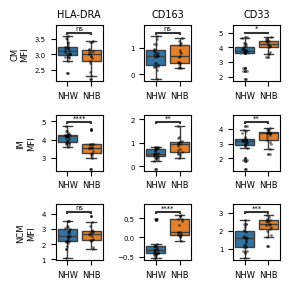

In [10]:
# assumes:
# - cols_sel already exists
# - dfp exists
# - Annotator imported
# - seaborn / matplotlib imported

# ---------------- protein renaming ----------------
protein_map = {
    'HLA-DR': 'HLA-DRA',   # antigen presentation
    'CD163': 'CD163',      # anti-inflammatory / immunoregulatory
    # 'CD16': 'FCGR3A',      # inflammatory / patrolling monocytes

    # 'CD11b': 'ITGAM',      # adhesion / migration
    # 'CD14': 'CD14',        # LPS co-receptor / innate immune response
    'CD33': 'CD33',        # suppressive myeloid context
}

id_cols = ['Patient ID', 'Age', 'Race & Ethnicity', 'Subtype', 'Diabetes', 'Obesity']

# -------- wide -> long --------
long = (
    dfp.loc[:, id_cols + cols_sel]
       .melt(id_vars=id_cols, value_vars=cols_sel,
             var_name='feature', value_name='value')
)

parts = long['feature'].astype(str).str.split('|')
long['celltype_raw'] = parts.str[0].str.strip()
long['celltype'] = parts.str[0].str.strip().str.strip('[]')
long['channel'] = parts.str[1].str.strip()
long['protein'] = long['channel'].str.split('___').str[-1]

# rename proteins to biological names
long['protein'] = long['protein'].map(lambda x: protein_map.get(x, x))

long['Race & Ethnicity'] = long['Race & Ethnicity'].astype(str).str.strip()

order = ['NHW', 'NHB']
pairs = [('NHW', 'NHB')]

# -------- layout: rows = cell types, cols = proteins --------
cell_order = ['[Classical Monocytes]','[Intermediate Monocytes]','[Non-Classical Monocytes]']#pd.unique(long['celltype_raw'])
prot_order = protein_map.values() 
#['HLA-DR','CD163','ITGAM']#pd.unique(long['protein'])

nrows = len(cell_order)
ncols = len(prot_order)

fig, axs = plt.subplots(
    nrows=nrows, ncols=ncols,
    figsize=(1 * ncols, 1 * nrows),  # short panels
    sharex=False, sharey=False
)

for i, cell_raw in enumerate(cell_order):
    for j, prot in enumerate(prot_order):
        ax = axs[i, j] if nrows > 1 else axs[j]

        tmp = long[
            (long['celltype_raw'] == cell_raw) &
            (long['protein'] == prot)
        ]

        if tmp.empty:
            ax.axis('off')
            continue

        sns.boxplot(
            data=tmp, x='Race & Ethnicity', y='value',
            hue='Race & Ethnicity', order=order,
            dodge=False, ax=ax, fliersize=1
        )
        sns.stripplot(
            data=tmp, x='Race & Ethnicity', y='value',
            order=order, color='k',
            size=2, alpha=.5, dodge=False, ax=ax
        )

        annot = Annotator(
            ax, pairs, data=tmp,
            x='Race & Ethnicity', y='value', order=order
        )
        annot.configure(
            test='Mann-Whitney',
            text_format='star',
            loc='inside',
            show_test_name=False,
            fontsize=5 
        )
        annot.apply_and_annotate()

        if ax.get_legend() is not None:
            ax.legend_.remove()

        # titles only on top row
        if i == 0:
            ax.set_title(prot, fontsize=7)

        # y-label only on first column
        if j == 0:
            pretty = 'CM' if cell_raw=='[Classical Monocytes]' else 'NCM' if cell_raw=='[Non-Classical Monocytes]' else 'IM' if cell_raw=='[Intermediate Monocytes]' else None
            ax.set_ylabel(f'{pretty}\nMFI', fontsize=6)
        else:
            ax.set_ylabel('')

        ax.set_xlabel('')
        ax.tick_params(axis='x', labelsize=6)
        ax.tick_params(axis='y', labelsize=5)

plt.tight_layout()
plt.savefig('plots/S5/MFI_Monocyte.pdf',
            bbox_inches='tight')
plt.show()